<a href="https://colab.research.google.com/github/Soumedha-28/Heart-Disease-Prediction/blob/main/Heart_disease_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ucimlrepo pandas numpy matplotlib seaborn scipy scikit-learn joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Download the UCI Heart Disease dataset

heart_disease = fetch_ucirepo(id=45)

# Extract features and target
X = heart_disease.data.features.copy()
y = heart_disease.data.targets.copy()

print("Dataset downloaded successfully!")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Dataset downloaded successfully!
Features shape: (303, 13)
Target shape: (303, 1)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [ ]:
# Combine features and target

df = X.copy()

df["target"] = pd.to_numeric(
    y.iloc[:, 0],
    errors="coerce"
).to_numpy()

# Convert all columns into numeric format
for column in df.columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Remove rows with missing target
df = df.dropna(subset=["target"]).copy()

# Convert target into binary classification
df["target"] = (df["target"] > 0).astype(int)

print("Dataset cleaned successfully!")

print("Dataset shape:", df.shape)

display(df.head())

Dataset cleaned successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [ ]:
import os

os.makedirs("data", exist_ok=True)

df.to_csv("data/heart.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total missing values:
6


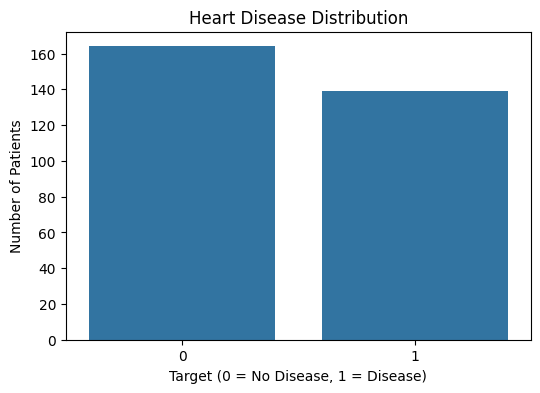

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="target")

plt.title("Heart Disease Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

plt.show()

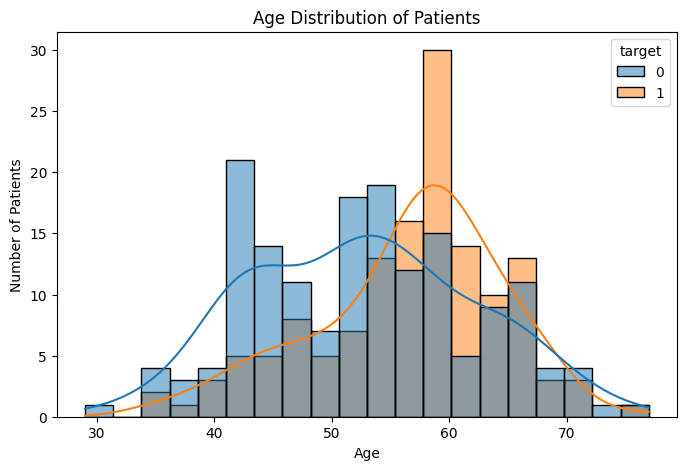

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="target",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

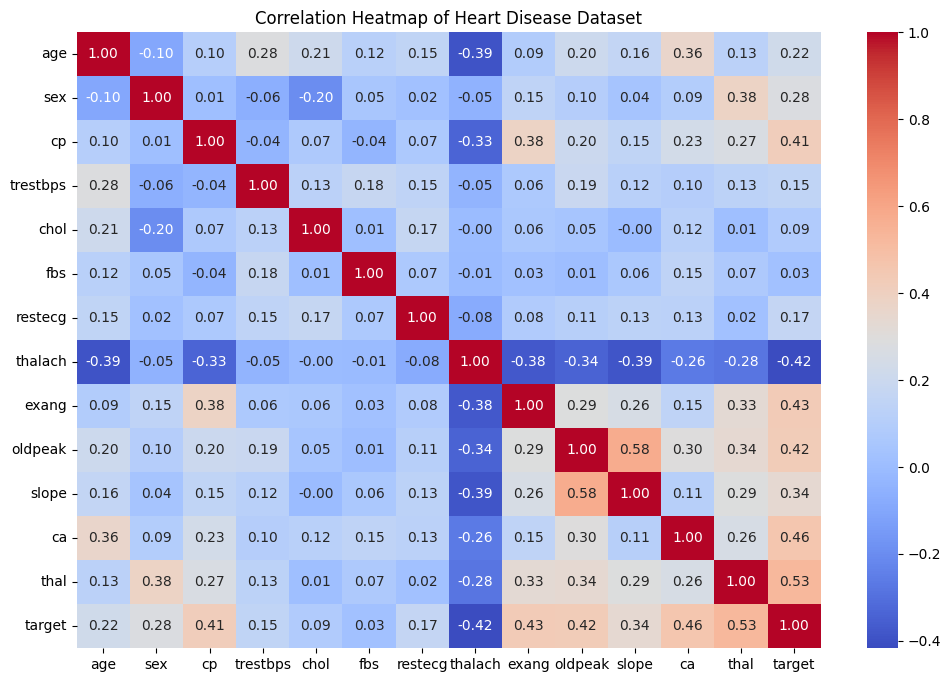

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Heart Disease Dataset")
plt.show()